<a href="https://colab.research.google.com/github/JoshEliell/ColabFiles/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos__274705_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión con Datos Categóricos
---


## Datos del Estudiante

*   Apellidos y Nombre: Victor Joshua Hernandez Ramom
*   Matrícula: 274705

---


** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
# Cargar de datos
df = pd.read_csv('/content/drive/MyDrive/ClassFiles/college.csv')

# Columnas especificas
df = df[['salary', 'cost', 'location']]

# Convertir 'location' a tipo de dato categorico
df['location'] = df['location'].astype('category')

# Mostrar estadísticas de las variables continuas
print("Estadísticas descriptivas:")
display(df[['salary', 'cost']].describe())

# Contar datos por categoría en 'location'
print("\nCantidad de datos por Location:")
print(df['location'].value_counts())

# Aplicar one-hot encoding (K-1) para evitar multicolinealidad
df_encoded = pd.get_dummies(df, columns=['location'], drop_first=True, dtype=int)

print("\nDataframe con One-Hot Encoding:")
display(df_encoded.head())

Estadísticas descriptivas:


,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000



Cantidad de datos por Location:
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64

Dataframe con One-Hot Encoding:


,salary,cost,location_NE,location_S,location_W
0,119000,189300,1,0,0
1,121000,189600,1,0,0
2,123000,188400,1,0,0
3,123000,188700,1,0,0
4,110000,194200,1,0,0


La función describe() nos dice que el salario medio de la muestra es 95898.82, con un mínimo de 74900 y un máximo de 123000.

Por el lado del costo, el promedio ronda los $142434.
Hay 4 categorías en la ubicación: NE (25), W (21), S (20), y MW (19).

Al aplicar One-Hot Encoding con drop_first=True, la categoría base eliminada es MW (Midwest). Se generaron columnas booleanas (o enteras) para location_NE, location_S y location_W.

# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




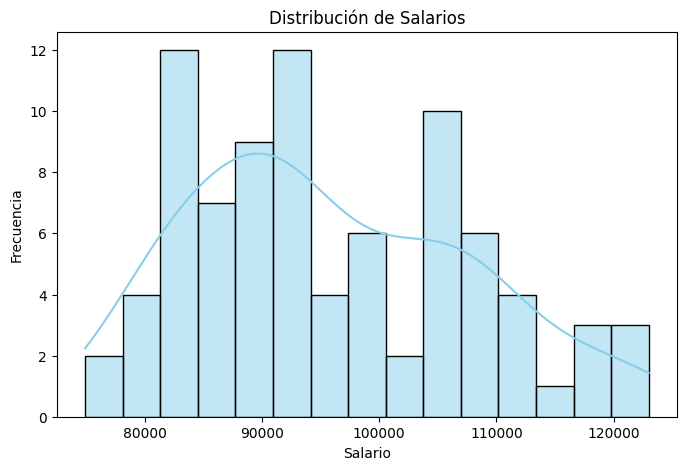

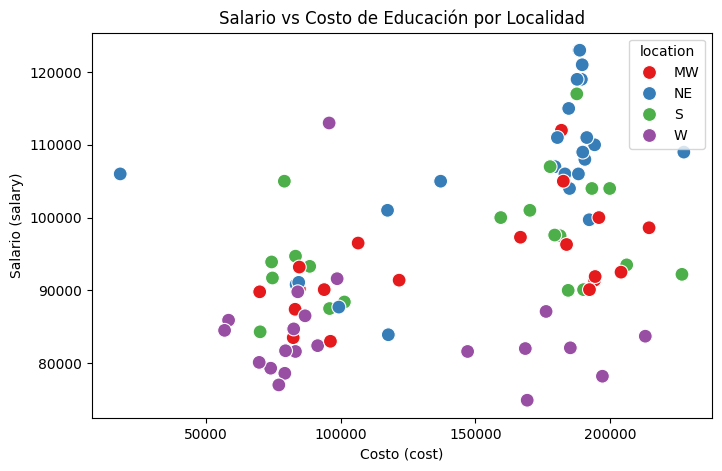

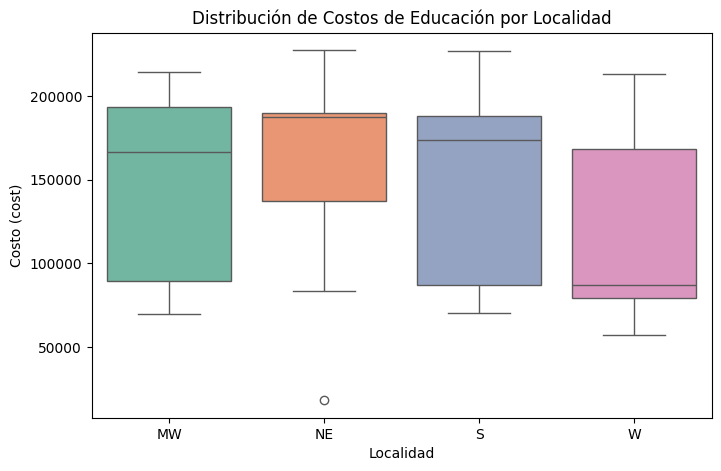

In [ ]:
# Histograma de la variable salary
plt.figure(figsize=(8, 5))
sns.histplot(df['salary'], bins=15, kde=True, color='skyblue')
plt.title('Distribución de Salarios')
plt.xlabel('Salario')
plt.ylabel('Frecuencia')
plt.show()

# Diagrama de dispersión de salary vs cost (4 colores distintos por location)
plt.figure(figsize=(8, 5))
sns.scatterplot(x='cost', y='salary', hue='location', data=df, palette='Set1', s=100)
plt.title('Salario vs Costo de Educación por Localidad')
plt.xlabel('Costo (cost)')
plt.ylabel('Salario (salary)')
plt.show()

# Boxplot del Costo (cost) por localidad (location)
plt.figure(figsize=(8, 5))
sns.boxplot(x='location', y='cost', hue='location', data=df, palette='Set2', legend=False)
plt.title('Distribución de Costos de Educación por Localidad')
plt.xlabel('Localidad')
plt.ylabel('Costo (cost)')
plt.show()

Histograma: La variable salary tiene una distribución sesgada a la derecha, donde la mayor parte de salarios de los egresados se ubica entre los 85000 y 100000.  

 Scatter plot (Salario vs Costo): Se ve una tendencia general positiva (a mayor costo educativo, mayor salario). Pero, observando los colores se ve que la region juega un papel crucial: la zona NE (rojo) concentra los costos y salarios mas altos, mientras que la zona W (morado), a pesar de tener costos educativos igual de elevados que NE, obtiene salarios mas bajos.   

 Boxplot (Costos por Localidad): Existen diferencias regionales. Las universidades en NE y W son las mas caras (medianas alrededor de 185000 y 170000 respectivamente), siendo NE la región mas consistente. Por el contrario, MW y S tienen medianas de costo mucho más bajas (cerca de 95000 y 115000), pero presentan cajas muy alargadas, lo que indica alta variabilidad.   

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [ ]:
# Defino variables independientes X y dependiente y
X = df_encoded.drop(columns=['salary'])
y = df_encoded['salary']

# Construir y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Imprimir el intercepto y los coeficientes
print(f"Intercepto: {modelo.intercept_:.2f}")

print("\nCoeficientes:")
for col, coef in zip(X.columns, modelo.coef_):
    print(f"{col}: {coef:.2f}")

Intercepto: 84988.72

Coeficientes:
cost: 0.06
location_NE: 12032.82
location_S: 2800.35
location_W: -7721.42


Intercepto (84988.72): Es el salario base estimado cuando todas las variables valen 0 (una escuela en la región de referencia MW con costo 0).  

 cost (0.06): Manteniendo la misma ubicación geografica, por cada valor adicional que cuesta la universidad, el salario estimado aumenta en 0.06 (o visto de forma más practica: por cada 10000 extra de costo, el salario sube unos 600).

 location_NE (12032.82): A igual costo educativo, estudiar en el Noreste (NE) genera en promedio 12032.82 mas de salario que estudiar en el Medio Oeste (MW).   

 location_S (2800.35): A igual costo educativo, estudiar en el Sur (S) se asocia con 2800.35 mas de salario en promedio que en MW.  

  location_W (-7721.42): A igual costo educativo, estudiar en el Oeste (W) reduce el salario estimado en 7721.42 en promedio respecto a MW.

  Por ejemplo, si sustituimos en la ecuacion una escuela que cuesta 150000. Si esta en MW (todas las dummy en 0) el salario estimado es 84988.72 + 0.06(150000) = 93988.72. Si esa misma escuela estuviera en NE (location_NE = 1), le sumamos los 12032.82 y sube a 106021.54.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

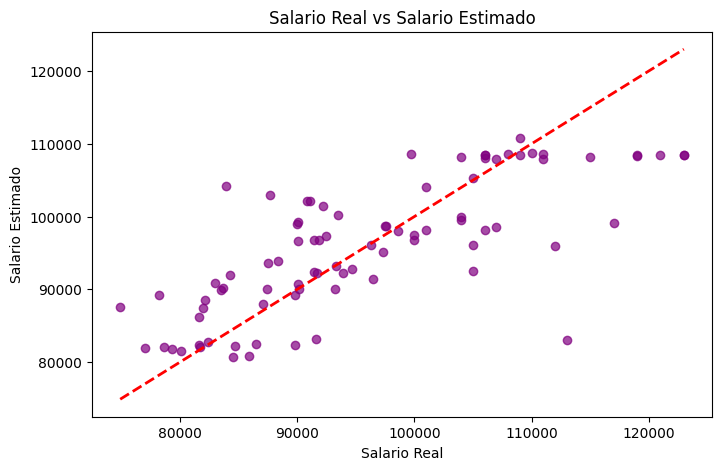

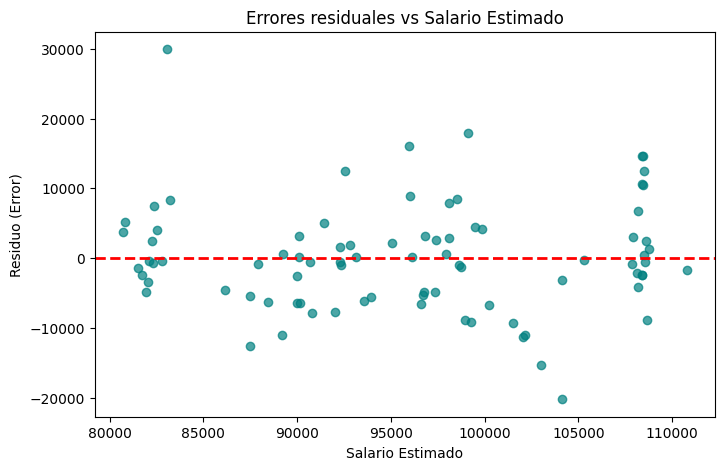

In [ ]:
# Predicciones
y_pred = modelo.predict(X)

# Calcular residuos
residuos = y - y_pred

# Visualización de predicciones salario estimado vs salario real
plt.figure(figsize=(8, 5))
plt.scatter(y, y_pred, color='purple', alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.title('Salario Real vs Salario Estimado')
plt.xlabel('Salario Real')
plt.ylabel('Salario Estimado')
plt.show()

# Grafica de los errores residuales vs predicciones
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuos, color='teal', alpha=0.7)
plt.axhline(0, color='red', linestyle='--', lw=2)
plt.title('Errores residuales vs Salario Estimado')
plt.xlabel('Salario Estimado')
plt.ylabel('Residuo (Error)')
plt.show()

Valores Reales vs Estimados: Se observa que la dispersion se agrupa alrededor de la línea diagonal roja, lo que significa que el modelo logra capturar la tendencia. No obstante, existe bastante error en las predicciones centrales ya que los puntos estan alejados de la recta perfecta.

Gráfica de Residuos: Los puntos estan distribuidos de manera aparentemente aleatoria arriba y abajo del cero, lo cual es bueno porque sugiere que los errores tienen varianza mas o menos constante (Homocedasticidad). Pero, algunos puntos superan los -15000 en el eje, lo cual son errores considerables.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [ ]:
# Calcular el Mean Squared Error (MSE)
mse = mean_squared_error(y, y_pred)
print(f"MSE: {mse:.2f}")

# Calcular R² Score
r2 = r2_score(y, y_pred)
print(f"R² Score: {r2:.4f}")

MSE: 60480269.15
R² Score: 0.5705


MSE (60480269.15) y RMSE (7776.91): Como el MSE está elevado al cuadrado, el número se ve gigante y es difícil de interpretar directamente. Al sacarle la raíz cuadrada (RMSE), obtenemos 7776.91 , lo que significa de forma sencilla que las predicciones salariales de nuestro modelo se equivocan, en promedio, por unos 7777 respecto al salario real.  

 R² Score (0.5705): Indica que el costo de la universidad y su ubicación geográfica logran explicar el 57.05% de las diferencias salariales entre los egresados. Es un ajuste moderado y aceptable, pero confirma que el 42.95% restante del salario depende de otros factores que no están en estos datos (como la carrera elegida, el prestigio de la universidad o el desempeño del estudiante).

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [ ]:
from statsmodels.formula.api import ols
import statsmodels.api as sm

#formula para evaluar 'location' en conjunto y por categoría:
formula_model = ols('salary ~ cost + C(location)', data=df).fit()

print("TABLA ANOVA (Efecto global de cada variable)")
tabla_anova = sm.stats.anova_lm(formula_model, typ=2)
display(tabla_anova)

print("\n RESUMEN DEL MODELO (Desglose por región vs MW)")
print(formula_model.summary())

TABLA ANOVA (Efecto global de cada variable)


,sum_sq,df,F,PR(>F)
C(location),4.071774e+09,3.0,21.121259,3.570975e-10
cost,7.878166e+08,1.0,12.259774,7.600629e-04
Residual,5.140823e+09,80.0,NaN,NaN



 RESUMEN DEL MODELO (Desglose por región vs MW)
                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           4.96e-14
Time:                        02:49:25   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

Impacto global de la Ubicación (C(location)): En la tabla ANOVA, su valor F es de 21.12 con un p-valor practicamente de cerO. Esto confirma estadísticamente que la zona geografica donde se estudia sí hace una diferencia real y muy fuerte en el salario futuro, siendo de hecho la variable que mss peso aporta al modelo.  

Impacto del Costo (cost): Arroja un p-valor de 0.00076 (< 0.05), lo que demuestra que el costo de la colegiatura tambien influye de forma real en el salario y no es producto del azar.   

Desglose por region (Tabla Summary): Al ver el detalle de cada region comparada contra la zona base (MW), comprobamos que estudiar en NE (p < 0.001) si garantiza ganar significativamente mas, y estudiar en W (p = 0.004) si implica ganar significativamente menos. En cambio, la región S tiene un p-valor de 0.279 (mayor a 0.05), lo que significa que la pequeña diferencia de +2,800 que vimos antes no es estadísticamente relevante, los egresados del Sur ganan practicamente lo mismo que los del Medio Oeste.  